<a href="https://colab.research.google.com/github/RomanLuja/ML/blob/main/08_trees_ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Заняття 8. Дерева, випадковий ліс і градієнтний бустинг

**Блок 3. Класичні моделі**

## 1. Перенавчання (overfitting)

Дерево без обмежень може ставити питання доти, доки в кожному листку не залишиться один клієнт.
Тоді на навчальних даних воно не помиляється — воно **запам'ятало** їх разом із випадковим шумом.
На нових даних така модель працює гірше.

- **Недонавчання:** модель надто проста, погано і на train, і на test.
- **Перенавчання:** модель надто складна, відмінно на train, гірше на test.
- Мета — **золота середина**, яку шукаємо, порівнюючи якість на даних, яких модель не бачила.

## 2. Ансамблі: багато дерев краще за одне

| Модель | Ідея | Аналогія |
|---|---|---|
| **Випадковий ліс** (Random Forest) | сотні дерев, кожне на випадковій частині рядків і ознак; відповідь — середнє | опитати 300 експертів, кожен бачив частину справи |
| **Градієнтний бустинг** (Gradient Boosting) | дерева будуються по черзі, кожне виправляє помилки попередніх | команда, де кожен наступний виправляє помилки попереднього |

На табличних бізнес-даних бустинг дуже часто найточніший. У `scikit-learn` швидка версія —
`HistGradientBoostingClassifier`; у роботі також використовують бібліотеки XGBoost, LightGBM, CatBoost.

Дерева й ансамблі **не потребують масштабування** ознак і самі знаходять нелінійні зв'язки та
взаємодії («пропущені платежі шкодять лише тим, хто платить вручну»).

## 3. Демонстрація: відтік підписників стрімінгу

Стрімінговий сервіс хоче знати, хто з підписників скасує підписку наступного місяця (`churned`).

In [1]:
# Підготовка: бібліотеки та функція завантаження даних (працює в Colab і локально)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data/"

def load_csv(name):
    """Читає CSV з поточної теки, з теки data/, з DATA_URL або просить завантажити файл у Colab."""
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)
    if DATA_URL:
        return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)
    from google.colab import files
    print(f"Натисніть «Choose files» і виберіть файл {name}")
    files.upload()
    return pd.read_csv(name)

In [2]:
import time
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

subs = load_csv("streaming_subscribers.csv")
print(subs.shape, "| частка відтоку:", round(subs["churned"].mean(), 3))
subs.head()

(7000, 15) | частка відтоку: 0.141


,subscriber_id,plan,monthly_fee_uah,tenure_months,payment_method,watch_hours_month,watch_hours_change_pct,devices,profiles,support_tickets_3m,failed_payments_6m,days_since_last_login,promo_signup,age_group,churned
0,S100000,basic,149,24,mobile_balance,13.8,51.0,3,2,0,0,20,0,25-34,0
1,S100001,standard,249,49,card_autopay,15.0,-15.0,2,3,0,0,22,0,35-44,0
2,S100002,premium,399,12,card_autopay,20.5,-16.0,1,2,1,0,3,1,45-54,0
3,S100003,basic,149,15,card_autopay,12.7,23.0,3,4,1,0,11,0,45-54,0
4,S100004,standard,249,7,card_autopay,16.0,-3.0,1,1,1,0,6,0,18-24,0


In [3]:
target = "churned"
cat = ["plan", "payment_method", "age_group"]
num = [c for c in subs.columns if c not in cat + [target, "subscriber_id"]]
s_tr, s_te = train_test_split(subs, test_size=0.25, random_state=42, stratify=subs[target])

# Для дерев категорії кодуємо так само one-hot; масштабування не потрібне
tree_prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", "passthrough", num)])

### Крок 1. Перенавчання наживо: глибина дерева

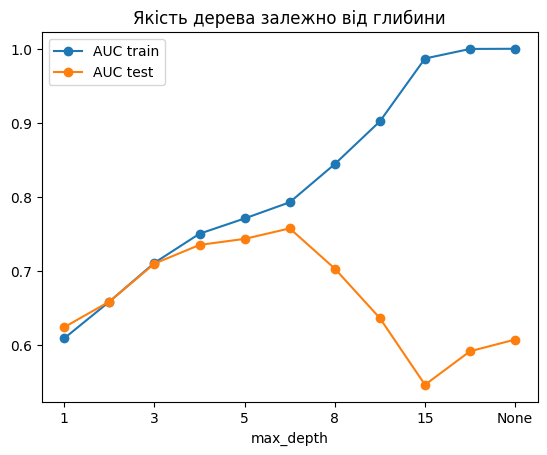

,max_depth,AUC train,AUC test
0,1,0.609,0.624
1,2,0.658,0.658
2,3,0.711,0.710
3,4,0.750,0.735
4,5,0.771,0.743
5,6,0.793,0.757
6,8,0.844,0.703
7,10,0.902,0.636
8,15,0.987,0.546
9,20,1.000,0.591


In [4]:
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]:
    m = Pipeline([("prep", tree_prep), ("clf", DecisionTreeClassifier(max_depth=depth, random_state=42))]).fit(s_tr, s_tr[target])
    rows.append({"max_depth": str(depth),
                 "AUC train": roc_auc_score(s_tr[target], m.predict_proba(s_tr)[:, 1]),
                 "AUC test": roc_auc_score(s_te[target], m.predict_proba(s_te)[:, 1])})
depth_table = pd.DataFrame(rows)
depth_table.plot(x="max_depth", y=["AUC train", "AUC test"], marker="o", title="Якість дерева залежно від глибини")
plt.show()
depth_table.round(3)

З ростом глибини якість на train росте аж до 1.0 (запам'ятовування), а на test спочатку росте,
потім падає. Найкраща глибина — там, де test найвищий. Дерево без обмеження (`None`) — класичне
перенавчання.

### Крок 2. Порівняння моделей

In [5]:
models = {
    "Логістична регресія": Pipeline([
        ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)])),
        ("clf", LogisticRegression(max_iter=1000))]),
    "Дерево (глибина 5)": Pipeline([("prep", tree_prep), ("clf", DecisionTreeClassifier(max_depth=5, random_state=42))]),
    "Випадковий ліс": Pipeline([("prep", tree_prep), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42))]),
    "Градієнтний бустинг": Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=42))]),
}
results = []
for name, m in models.items():
    start = time.time()
    m.fit(s_tr, s_tr[target])
    results.append({"модель": name,
                    "AUC train": roc_auc_score(s_tr[target], m.predict_proba(s_tr)[:, 1]),
                    "AUC test": roc_auc_score(s_te[target], m.predict_proba(s_te)[:, 1]),
                    "секунд": time.time() - start})
pd.DataFrame(results).round(3)

,модель,AUC train,AUC test,секунд
0,Логістична регресія,0.757,0.762,0.166
1,Дерево (глибина 5),0.771,0.743,0.086
2,Випадковий ліс,0.967,0.803,2.465
3,Градієнтний бустинг,0.978,0.784,0.426


Порівняйте моделі за **AUC test**. Ансамблі зазвичай найкращі, бо ловлять нелінійні ефекти й
взаємодії. Різниця між train і test показує, наскільки модель «запам'ятала» навчальні дані.

**Чесне зауваження:** якщо логістична регресія відстає лише трохи, у бізнесі її часто обирають —
вона простіша, швидша і її коефіцієнти легко пояснити. Вибір моделі — це компроміс точності й
зрозумілості.

### Крок 3. Важливість ознак у випадковому лісі

Ліс рахує, наскільки кожна ознака в середньому покращує розбиття в деревах. Це швидкий огляд;
надійніший спосіб (permutation importance).

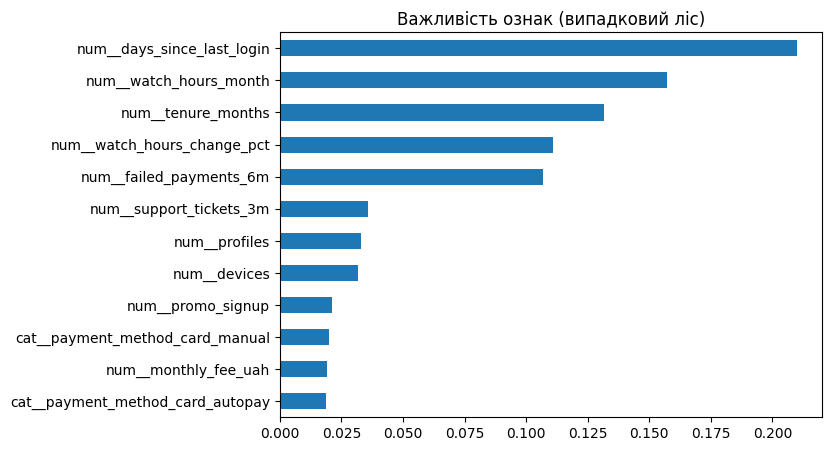

,0
num__days_since_last_login,0.210
num__watch_hours_month,0.157
num__tenure_months,0.132
num__watch_hours_change_pct,0.111
num__failed_payments_6m,0.107


In [6]:
rf = models["Випадковий ліс"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_,
                index=rf.named_steps["prep"].get_feature_names_out()).sort_values()
imp.tail(12).plot.barh(figsize=(7, 5), title="Важливість ознак (випадковий ліс)")
plt.show()
imp.sort_values(ascending=False).head(5).round(3)

Найважливіші ознаки — давність останнього входу, перегляд годин і стаж підписки. Важливість **не
показує напрямок** впливу (підвищує чи знижує ризик) — лише силу.

---
## 4. Практика: дефолти за кредитами

Беремо `bank_loans.csv`, з яким працювали на занятті 7.

In [7]:
loans = load_csv("bank_loans.csv")
loans["payment_to_income"] = (loans["loan_amount_uah"] / loans["term_months"]) / loans["monthly_income_uah"]
l_target = "default"
l_cat = ["employment_type", "region"]
l_num = ["age", "monthly_income_uah", "years_employed", "loan_amount_uah", "term_months", "interest_rate",
         "credit_history_years", "prior_defaults", "open_loans", "has_collateral", "payment_to_income"]
l_tr, l_te = train_test_split(loans, test_size=0.25, random_state=42, stratify=loans[l_target])

### Завдання 1. Перенавчання дерева

Побудуйте таблицю і графік AUC train / AUC test для дерев глибиною 1, 2, 3, 4, 5, 6, 8, 10, 15, None.
Яка глибина найкраща? З якої глибини починається перенавчання?

In [8]:
# Ваш код тут

### Завдання 2. Турнір моделей

Порівняйте за AUC test і часом навчання: логістичну регресію (з масштабуванням), найкраще дерево
із завдання 1, випадковий ліс (`n_estimators=300, min_samples_leaf=5, random_state=42`) і
`HistGradientBoostingClassifier(random_state=42)`.

In [9]:
# Ваш код тут

### Завдання 3. Чесний висновок

Подивіться на результат турніру. Чи переміг складний метод? Якщо ні — чому це могло статися?
*Підказка:* згадайте, як влаштований ризик дефолту: чи є в ньому складні взаємодії, чи він
майже «лінійно» залежить від кількох ознак (частка платежу в доході, прострочення в минулому)?
Яку модель ви запропонували б банку і чому?

In [10]:
# Випадковий ліс трохи кращий за логістичну регресію (приблизно +0.01 AUC), а бустинг «з коробки»
# навіть гірший: AUC train майже 1.0 - він перенавчився (налаштування - заняття 9).
# Ризик дефолту майже монотонно залежить від кількох ознак, тому ансамблям мало що «додатково знаходити».
# Для банку розумний вибір - логістична регресія: регулятор вимагає пояснюваності, а різниця мала.
# Ваш код тут

### Завдання 4. Важливість ознак

Побудуйте графік важливості ознак випадкового лісу (топ-10). Чи збігаються найважливіші ознаки з
найбільшими (за модулем) коефіцієнтами логістичної регресії?

In [11]:
# Ваш код тут

---
## Підсумок

- Складна модель може **запам'ятати** навчальні дані — перевіряємо на test.
- Випадковий ліс усереднює багато дерев; бустинг будує дерева, що виправляють помилки одне одного.
- Ансамблі часто найточніші на табличних даних, але **не завжди**: якщо зв'язок простий, проста
  модель не гірша і її легше пояснити.
- Важливість ознак показує силу впливу, але не напрямок.